####1 Downloading everything and inspecting what's actually in each file

In [ ]:
import pandas as pd
import requests
from io import BytesIO

BASE_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/"

files_to_try = ["DEMO_J", "BMX_J", "BPX_J", "GLU_J", "GHB_J", "DIQ_J", "INS_J"]

datasets = {}
for code in files_to_try:
    url = BASE_URL + code + ".XPT"
    try:
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        df = pd.read_sas(BytesIO(r.content), format="xport")
        datasets[code] = df
        print(f"✓ {code}: {df.shape[0]} rows, {df.shape[1]} columns")
        print(f"  Columns: {list(df.columns)}\n")
    except Exception as e:
        print(f"✗ {code}: FAILED — {e}\n")

✓ DEMO_J: 9254 rows, 46 columns
  Columns: ['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMQADFC', 'DMDBORN4', 'DMDCITZN', 'DMDYRSUS', 'DMDEDUC3', 'DMDEDUC2', 'DMDMARTL', 'RIDEXPRG', 'SIALANG', 'SIAPROXY', 'SIAINTRP', 'FIALANG', 'FIAPROXY', 'FIAINTRP', 'MIALANG', 'MIAPROXY', 'MIAINTRP', 'AIALANGA', 'DMDHHSIZ', 'DMDFMSIZ', 'DMDHHSZA', 'DMDHHSZB', 'DMDHHSZE', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA', 'INDHHIN2', 'INDFMIN2', 'INDFMPIR']

✓ BMX_J: 8704 rows, 21 columns
  Columns: ['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP']

✓ BPX_J: 8704 rows, 21 columns
  Columns: ['SEQN', 'PEASCCT1', 'BPXCHR', 'BPAARM', 'BPACSZ', 'BPXPLS', 'BPXPULS', 'BPXPTY', 'BPXML1', 'BPXSY1', 'BPX

In [ ]:
#2 Checking specifically for skinfold data in BMX_J
bmx_cols = datasets["BMX_J"].columns.tolist()
skinfold_cols = [c for c in bmx_cols if "TRI" in c or "SUB" in c or "SKIN" in c.upper()]
print("Possible skinfold columns:", skinfold_cols)

Possible skinfold columns: []


In [ ]:
#3 Merging all components on SEQN
# Start from the fasting-lab subsample (GLU_J/INS_J), since Glucose and
# Insulin are essential predictors — every other file is left-joined onto
# this base, so the fasting restriction determines final sample size.
merged = datasets["GLU_J"][["SEQN", "LBXGLU"]].merge(
    datasets["INS_J"][["SEQN", "LBXIN"]], on="SEQN", how="inner"
)
merged = merged.merge(datasets["DEMO_J"][["SEQN", "RIAGENDR", "RIDAGEYR", "RIDRETH3", "RIDEXPRG"]], on="SEQN", how="left")
merged = merged.merge(datasets["BMX_J"][["SEQN", "BMXBMI"]], on="SEQN", how="left")
merged = merged.merge(datasets["BPX_J"][["SEQN", "BPXDI1"]], on="SEQN", how="left")
merged = merged.merge(datasets["GHB_J"][["SEQN", "LBXGH"]], on="SEQN", how="left")
merged = merged.merge(datasets["DIQ_J"][["SEQN", "DIQ010"]], on="SEQN", how="left")

print("Shape after merge:", merged.shape)

Shape after merge: (3036, 11)


In [ ]:
#4 Applying inclusion/exclusion criteria
# Age >= 21, matching PIDD's stated inclusion criterion
merged = merged[merged["RIDAGEYR"] >= 21]

# Exclude currently pregnant respondents (RIDEXPRG == 1)
merged = merged[merged["RIDEXPRG"] != 1]

print("Shape after age/pregnancy filters:", merged.shape)

Shape after age/pregnancy filters: (2482, 11)


In [ ]:
# @title
#5 Defining Outcome using clinical criteria
# Exclude ambiguous "borderline" self-reported diabetes responses (DIQ010 == 3)
merged = merged[merged["DIQ010"] != 3]

merged["Outcome"] = (
    (merged["LBXGLU"] >= 126) |
    (merged["LBXGH"] >= 6.5) |
    (merged["DIQ010"] == 1)
).astype(int)

print("Outcome distribution:")
print(merged["Outcome"].value_counts(normalize=True))
print("\nShape after Outcome definition:", merged.shape)

Outcome distribution:
Outcome
0    0.76718
1    0.23282
Name: proportion, dtype: float64

Shape after Outcome definition: (2401, 12)


In [ ]:
#5 Outcome Definition — REVISED
# Original definition included fasting Glucose >= 126 mg/dL as one of three
# criteria. Since Glucose is also a model feature, this created circularity:
# a diagnostic check confirmed 316 of 447 diabetic-labeled training patients
# (70.7%) were positive ONLY via the Glucose criterion, meaning the model
# could substantially reconstruct its own training label from one feature
# rather than learning a genuine multi-feature relationship. The Glucose
# criterion is therefore dropped from the Outcome definition; HbA1c and
# self-reported diagnosis remain, as neither is used as a model feature.
merged = merged[merged["DIQ010"] != 3]  # exclude ambiguous "borderline" responses

merged["Outcome"] = (
    (merged["LBXGH"] >= 6.5) |
    (merged["DIQ010"] == 1)
).astype(int)

print("Outcome distribution (revised):")
print(merged["Outcome"].value_counts(normalize=True))
print("\nShape after Outcome definition:", merged.shape)

Outcome distribution (revised):
Outcome
0    0.792586
1    0.207414
Name: proportion, dtype: float64

Shape after Outcome definition: (2401, 12)


In [ ]:
#6 Renaming to match PIDD naming, treating physiologically implausible zeros as missing
merged = merged.rename(columns={
    "LBXGLU": "Glucose",
    "BPXDI1": "BloodPressure",
    "BMXBMI": "BMI",
    "LBXIN": "Insulin",
    "RIDAGEYR": "Age",
    "RIAGENDR": "Gender",       # kept for demographic reporting, not a model feature
    "RIDRETH3": "Race"          # kept for demographic reporting, not a model feature
})

# Diastolic BP of 0 is a known NHANES artefact (auscultatory gap), not a true zero —
# same treat-as-missing convention already established for PIDD
merged.loc[merged["BloodPressure"] == 0, "BloodPressure"] = None

print(merged[["Glucose", "BloodPressure", "BMI", "Insulin", "Age", "Outcome"]].describe())
print("\nGender distribution:\n", merged["Gender"].value_counts())
print("\nRace distribution:\n", merged["Race"].value_counts())

           Glucose  BloodPressure          BMI      Insulin          Age  \
count  2301.000000   2.111000e+03  2355.000000  2257.000000  2401.000000   
mean    114.657540   7.233633e+01    29.806624    14.750084    51.840900   
std      37.952328   1.316561e+01     7.438845    21.484412    17.398674   
min      47.000000   5.397605e-79    14.900000     0.710000    21.000000   
25%      97.000000   6.400000e+01    24.700000     6.210000    37.000000   
50%     104.000000   7.200000e+01    28.500000     9.900000    53.000000   
75%     116.000000   8.000000e+01    33.600000    16.380000    65.000000   
max     421.000000   1.360000e+02    86.200000   485.100000    80.000000   

           Outcome  
count  2401.000000  
mean      0.207414  
std       0.405539  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       0.000000  
max       1.000000  

Gender distribution:
 Gender
2.0    1234
1.0    1167
Name: count, dtype: int64

Race distribution:
 Race
3.0    796
4.0    57

In [ ]:

#7 Building the two final feature sets

# Core comparison set — the 5 features shared with your reduced PIDD model
core_cols = ["Glucose", "BloodPressure", "BMI", "Insulin", "Age", "Outcome"]
nhanes_core = merged[core_cols].copy()

# Full NHANES set — core features plus Gender and Race
full_cols = ["Glucose", "BloodPressure", "BMI", "Insulin", "Age", "Gender", "Race", "Outcome"]
nhanes_full = merged[full_cols].copy()

print("Core dataset shape:", nhanes_core.shape)
print("Full dataset shape:", nhanes_full.shape)

Core dataset shape: (2401, 6)
Full dataset shape: (2401, 8)


In [ ]:
#8 Sex/Race label mapping, counts, and missingness check
gender_labels = {1: "Male", 2: "Female"}
race_labels = {
    1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
    4: "Non-Hispanic Black", 6: "Non-Hispanic Asian", 7: "Other/Multi-Racial"
}

print("Missing Gender values:", nhanes_full["Gender"].isnull().sum())
print("Missing Race values:", nhanes_full["Race"].isnull().sum())

gender_counts = nhanes_full["Gender"].map(gender_labels).value_counts()
race_counts = nhanes_full["Race"].map(race_labels).value_counts()

print("\n", gender_counts)
print("\n", race_counts)

Missing Gender values: 0
Missing Race values: 0

 Gender
Female    1234
Male      1167
Name: count, dtype: int64

 Race
Non-Hispanic White    796
Non-Hispanic Black    575
Mexican American      337
Non-Hispanic Asian    328
Other Hispanic        228
Other/Multi-Racial    137
Name: count, dtype: int64


In [ ]:
#X Mapping NHANES codes to readable labels for reporting
gender_labels = {1: "Male", 2: "Female"}
race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other/Multi-Racial"
}

# Using nhanes_full (or merged, if Gender/Race live there) — adjust variable
# name to whichever DataFrame currently holds these two columns
gender_counts = nhanes_full["Gender"].map(gender_labels).value_counts()
race_counts = nhanes_full["Race"].map(race_labels).value_counts()

print(gender_counts)
print("\n", race_counts)

Gender
Female    1234
Male      1167
Name: count, dtype: int64

 Race
Non-Hispanic White    796
Non-Hispanic Black    575
Mexican American      337
Non-Hispanic Asian    328
Other Hispanic        228
Other/Multi-Racial    137
Name: count, dtype: int64


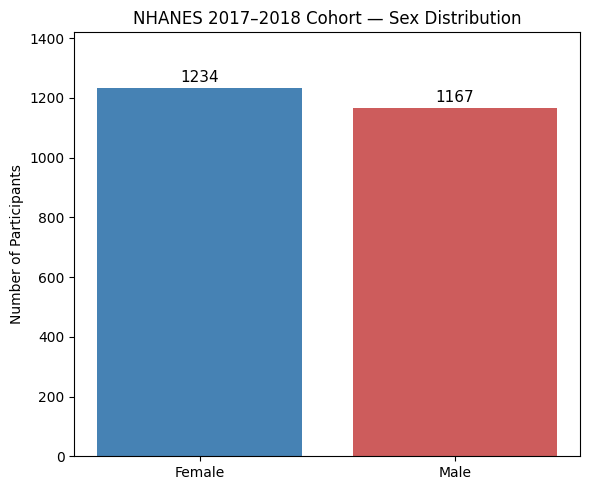

In [ ]:
#9
#Sex distribution bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
bars = plt.bar(gender_counts.index, gender_counts.values, color=["steelblue", "indianred"])

# Annotate each bar with its exact count, matching the style of your
# earlier feature importance / comparison charts
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 10, f"{int(height)}",
              ha="center", va="bottom", fontsize=11)

plt.title("NHANES 2017–2018 Cohort — Sex Distribution")
plt.ylabel("Number of Participants")
plt.ylim(0, max(gender_counts.values) * 1.15)
plt.tight_layout()
plt.savefig("NHANES_Fig5_1_Sex_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

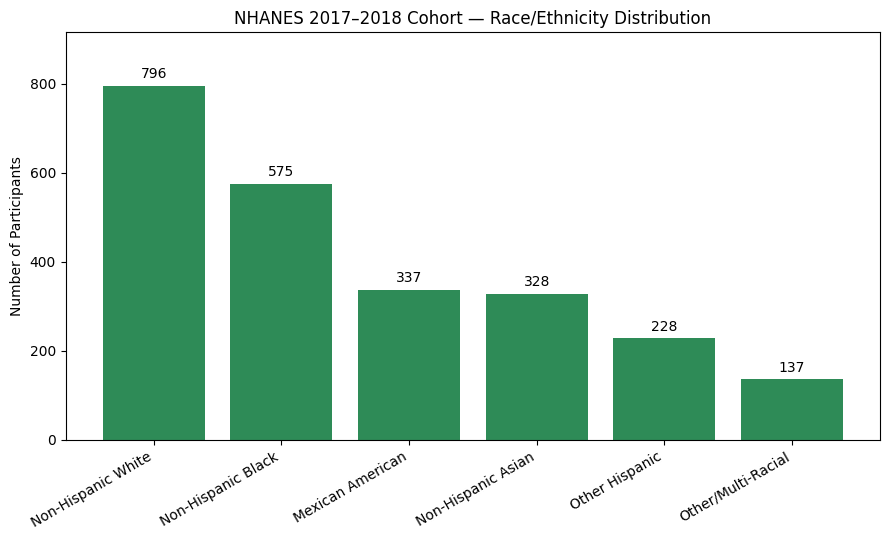

In [ ]:
#10
#Race/ethnicity distribution bar chart
plt.figure(figsize=(9, 5.5))
bars = plt.bar(race_counts.index, race_counts.values, color="seagreen")

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 10, f"{int(height)}",
              ha="center", va="bottom", fontsize=10)

plt.title("NHANES 2017–2018 Cohort — Race/Ethnicity Distribution")
plt.ylabel("Number of Participants")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, max(race_counts.values) * 1.15)
plt.tight_layout()
plt.savefig("NHANES_Fig5_2_Race_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
DRIVE_PATH = "/content/drive/MyDrive/Capstone/Data_2"

nhanes_core.to_csv(DRIVE_PATH + "NHANES_core_raw.csv", index=False)
nhanes_full.to_csv(DRIVE_PATH + "NHANES_full_raw.csv", index=False)

print("Saved raw core and full NHANES datasets to Drive")

Saved raw core and full NHANES datasets to Drive


In [ ]:
#8 Fixing the near-zero BloodPressure artifact
import numpy as np

nhanes_core.loc[nhanes_core["BloodPressure"] < 1, "BloodPressure"] = np.nan
nhanes_full.loc[nhanes_full["BloodPressure"] < 1, "BloodPressure"] = np.nan

print(nhanes_core["BloodPressure"].describe())

count    2099.000000
mean       72.749881
std        12.009364
min        32.000000
25%        66.000000
50%        72.000000
75%        80.000000
max       136.000000
Name: BloodPressure, dtype: float64


# EDA

In [ ]:
#9 NHANES Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Shared features used for PIDD-NHANES comparison
features = ["Glucose", "BloodPressure", "BMI", "Insulin", "Age"]

print("NHANES Core Dataset Shape:", nhanes_core.shape)
print("\nData Types:")
print(nhanes_core.dtypes)

print("\nFirst 5 rows:")
display(nhanes_core.head())

NHANES Core Dataset Shape: (2401, 6)

Data Types:
Glucose          float64
BloodPressure    float64
BMI              float64
Insulin          float64
Age              float64
Outcome            int64
dtype: object

First 5 rows:


,Glucose,BloodPressure,BMI,Insulin,Age,Outcome
1,107.0,68.0,21.3,5.28,56.0,0
2,91.0,62.0,24.5,3.94,22.0,0
3,89.0,88.0,22.0,4.89,45.0,0
5,104.0,68.0,35.9,57.60,60.0,0
6,101.0,68.0,23.8,7.04,60.0,0


In [ ]:
#10 Descriptive statistics

desc = nhanes_core[features].describe().T

# Add median and missingness
desc["median"] = nhanes_core[features].median()
desc["missing_n"] = nhanes_core[features].isnull().sum()
desc["missing_%"] = (
    nhanes_core[features].isnull().mean() * 100
)

desc = desc[
    ["count", "mean", "std", "min", "25%", "median",
     "75%", "max", "missing_n", "missing_%"]
]

display(desc.round(2))

,count,mean,std,min,25%,median,75%,max,missing_n,missing_%
Glucose,2301.0,114.66,37.95,47.00,97.00,104.0,116.00,421.0,100,4.16
BloodPressure,2099.0,72.75,12.01,32.00,66.00,72.0,80.00,136.0,302,12.58
BMI,2355.0,29.81,7.44,14.90,24.70,28.5,33.60,86.2,46,1.92
Insulin,2257.0,14.75,21.48,0.71,6.21,9.9,16.38,485.1,144,6.00
Age,2401.0,51.84,17.40,21.00,37.00,53.0,65.00,80.0,0,0.00


,Count,Percentage
Non-diabetic,1903,79.26
Diabetic,498,20.74


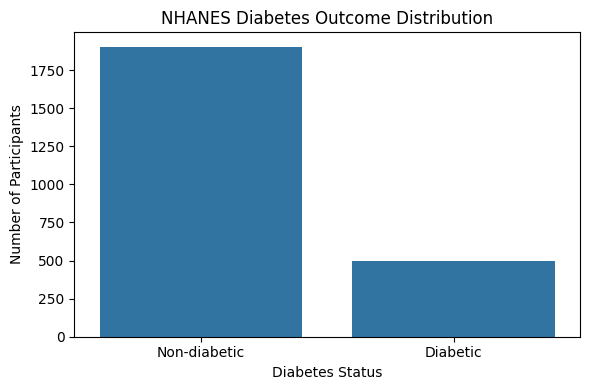

In [ ]:
#11 Outcome distribution

outcome_counts = nhanes_core["Outcome"].value_counts().sort_index()
outcome_percent = (
    nhanes_core["Outcome"].value_counts(normalize=True)
    .sort_index() * 100
)

class_table = pd.DataFrame({
    "Count": outcome_counts,
    "Percentage": outcome_percent
})

class_table.index = ["Non-diabetic", "Diabetic"]

display(class_table.round(2))

# Plot
plt.figure(figsize=(6, 4))
sns.countplot(data=nhanes_core, x="Outcome")
plt.xticks([0, 1], ["Non-diabetic", "Diabetic"])
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Participants")
plt.title("NHANES Diabetes Outcome Distribution")
plt.tight_layout()
plt.show()

,Missing Values,Missing Percentage
Glucose,100,4.16
BloodPressure,302,12.58
BMI,46,1.92
Insulin,144,6.00
Age,0,0.00


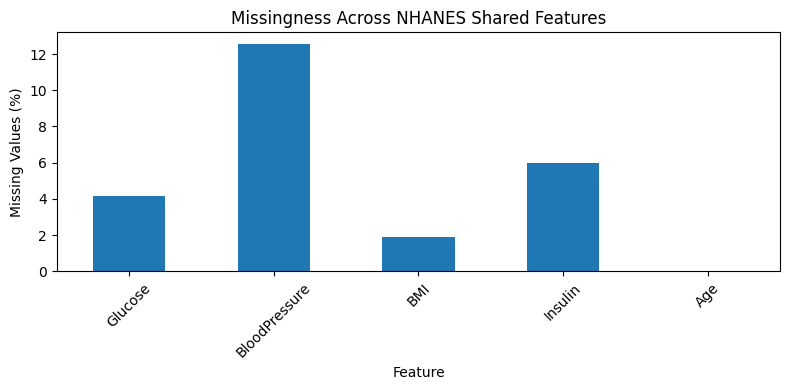

In [ ]:
#12 Missing values

missing = pd.DataFrame({
    "Missing Values": nhanes_core[features].isnull().sum(),
    "Missing Percentage": (
        nhanes_core[features].isnull().mean() * 100
    )
})

display(missing.round(2))

# Missingness plot
plt.figure(figsize=(8, 4))
missing["Missing Percentage"].plot(kind="bar")
plt.ylabel("Missing Values (%)")
plt.xlabel("Feature")
plt.title("Missingness Across NHANES Shared Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

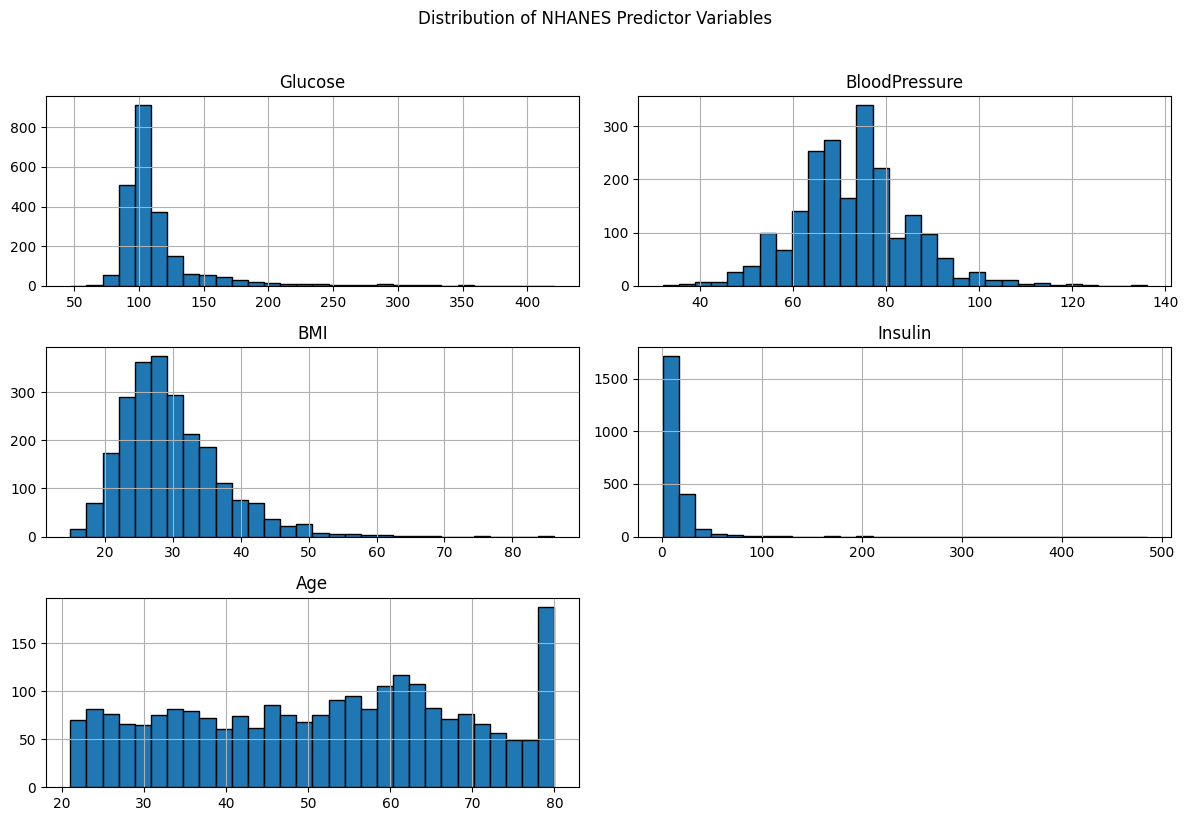

In [ ]:
#13 Histograms for shared predictors

nhanes_core[features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of NHANES Predictor Variables", y=1.02)
plt.tight_layout()
plt.show()

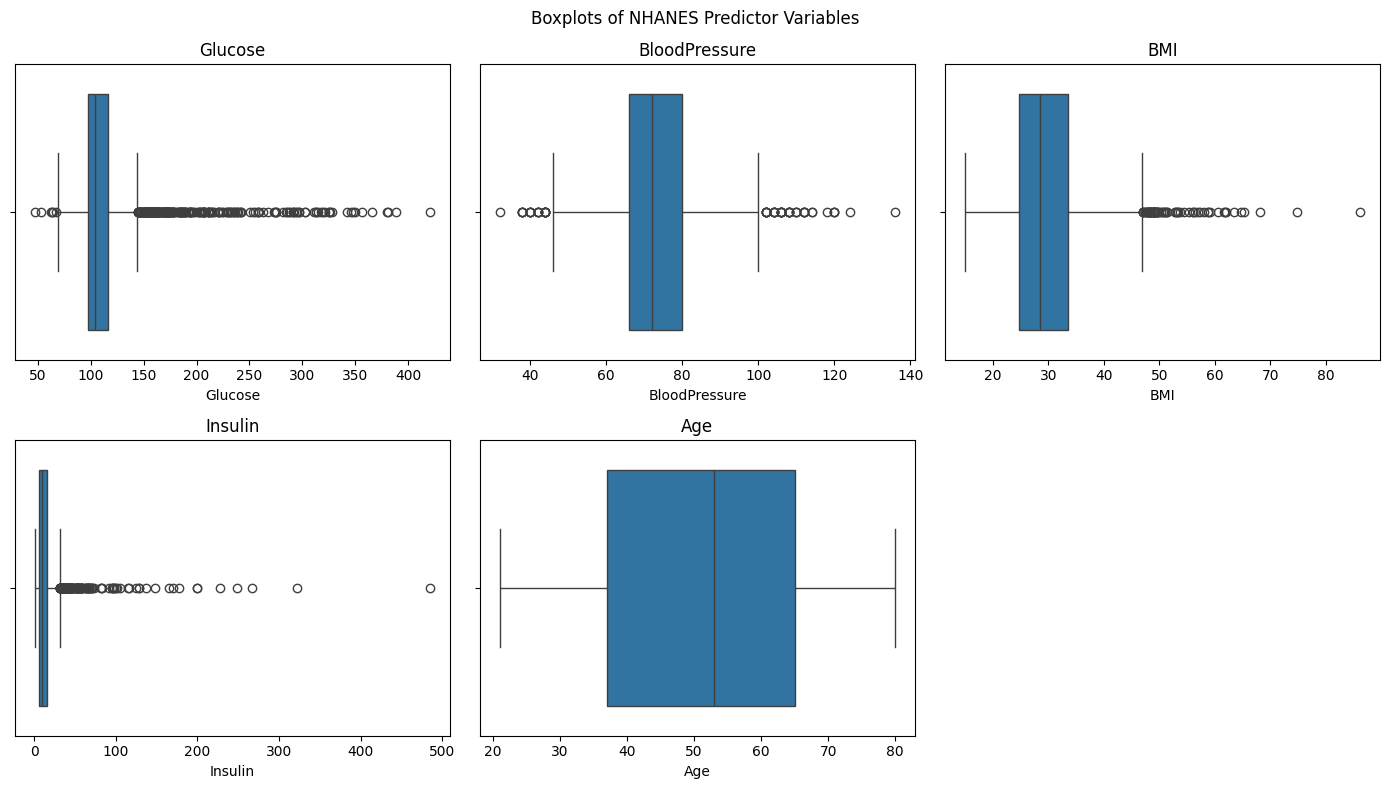

In [ ]:
#14 Boxplots

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        x=nhanes_core[feature],
        ax=axes[i]
    )
    axes[i].set_title(feature)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.suptitle("Boxplots of NHANES Predictor Variables")
plt.tight_layout()
plt.show()

In [ ]:
#15 Potential outliers using the IQR rule

outlier_results = []

for feature in features:
    values = nhanes_core[feature].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = values[(values < lower) | (values > upper)]

    outlier_results.append({
        "Feature": feature,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": len(outliers),
        "Outlier %": len(outliers) / len(values) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table.round(2))

,Glucose,BloodPressure,BMI,Insulin,Age,Outcome
Glucose,1.000,0.031,0.190,0.245,0.222,0.624
BloodPressure,0.031,1.000,0.110,0.043,-0.022,-0.040
BMI,0.190,0.110,1.000,0.305,-0.026,0.185
Insulin,0.245,0.043,0.305,1.000,0.041,0.226
Age,0.222,-0.022,-0.026,0.041,1.000,0.324
Outcome,0.624,-0.040,0.185,0.226,0.324,1.000


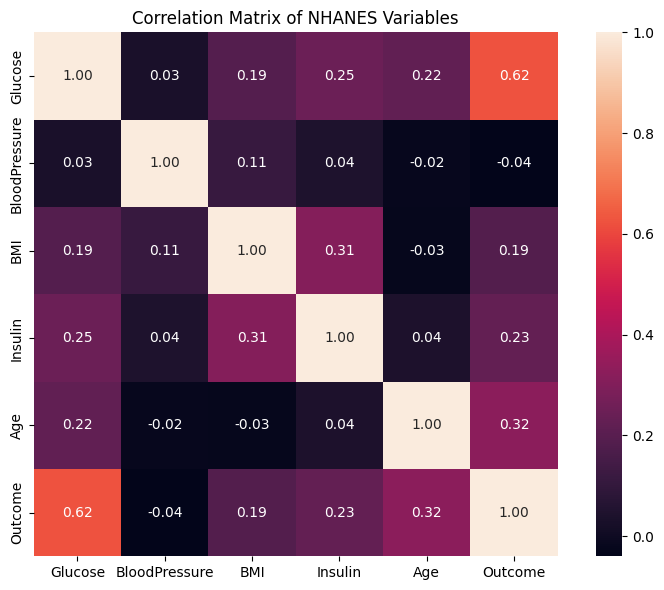

In [ ]:
#16 Pearson correlation matrix

corr = nhanes_core[
    features + ["Outcome"]
].corr()

display(corr.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix of NHANES Variables")
plt.tight_layout()
plt.show()

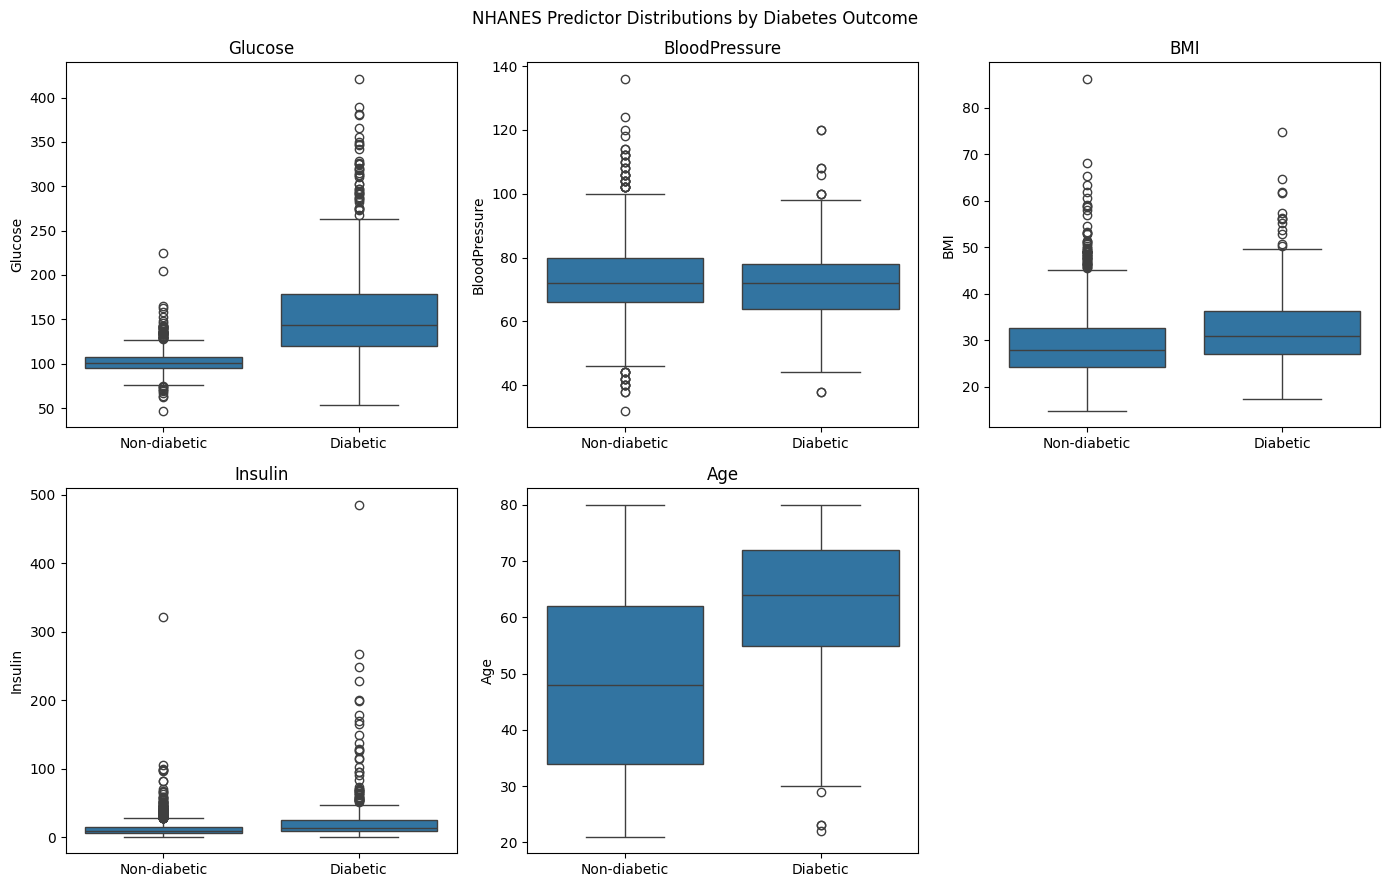

In [ ]:
#18 Boxplots by Outcome

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for i, feature in enumerate(features):

    sns.boxplot(
        data=nhanes_core,
        x="Outcome",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(
        ["Non-diabetic", "Diabetic"]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("")

fig.delaxes(axes[-1])

plt.suptitle(
    "NHANES Predictor Distributions by Diabetes Outcome"
)

plt.tight_layout()
plt.show()

In [ ]:
# Potential outliers using the IQR rule

outlier_results = []

for feature in features:
    values = nhanes_core[feature].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = values[(values < lower) | (values > upper)]

    outlier_results.append({
        "Feature": feature,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": len(outliers),
        "Outlier %": len(outliers) / len(values) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table.round(2))

,Feature,Lower Bound,Upper Bound,Potential Outliers,Outlier %
0,Glucose,68.50,144.50,251,10.91
1,BloodPressure,45.00,101.00,57,2.72
2,BMI,11.35,46.95,71,3.01
3,Insulin,-9.04,31.64,158,7.00
4,Age,-5.00,107.00,0,0.00


In [ ]:
#19 Mean and median of predictors by Outcome

means_by_outcome = (
    nhanes_core.groupby("Outcome")[features]
    .mean()
    .T
)

medians_by_outcome = (
    nhanes_core.groupby("Outcome")[features]
    .median()
    .T
)

comparison = pd.DataFrame({
    "Non-diabetic Mean": means_by_outcome[0],
    "Diabetic Mean": means_by_outcome[1],
    "Non-diabetic Median": medians_by_outcome[0],
    "Diabetic Median": medians_by_outcome[1]
})

display(comparison.round(2))

,Non-diabetic Mean,Diabetic Mean,Non-diabetic Median,Diabetic Median
Glucose,102.52,160.82,101.00,144.00
BloodPressure,72.99,71.79,72.00,72.00
BMI,29.10,32.50,27.90,31.00
Insulin,12.25,24.20,9.12,13.94
Age,48.96,62.87,48.00,64.00


In [ ]:
gender_labels = {
    1: "Male",
    2: "Female"
}

race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other/Multi-Racial"
}

nhanes_demo = nhanes_full.copy()

nhanes_demo["Gender_Label"] = (
    nhanes_demo["Gender"].map(gender_labels)
)

nhanes_demo["Race_Label"] = (
    nhanes_demo["Race"].map(race_labels)
)

print("Gender Distribution")
display(
    nhanes_demo["Gender_Label"]
    .value_counts()
    .to_frame("Count")
)

print("Race/Ethnicity Distribution")
display(
    nhanes_demo["Race_Label"]
    .value_counts()
    .to_frame("Count")
)

Gender Distribution


,Count
Gender_Label,
Female,1234
Male,1167


Race/Ethnicity Distribution


,Count
Race_Label,
Non-Hispanic White,796
Non-Hispanic Black,575
Mexican American,337
Non-Hispanic Asian,328
Other Hispanic,228
Other/Multi-Racial,137


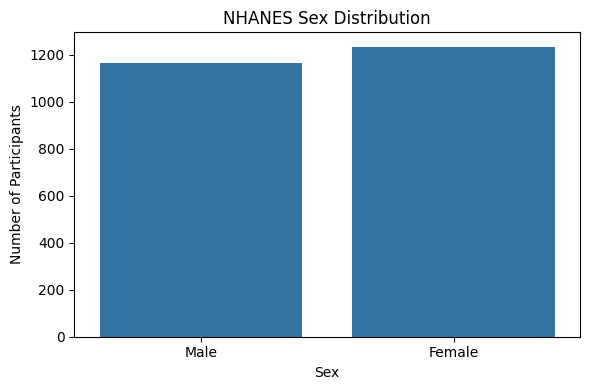

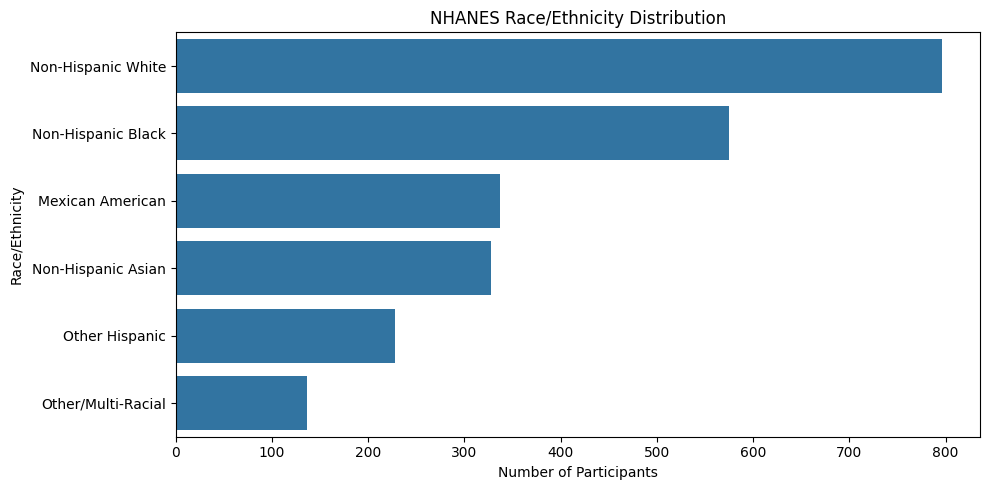

In [ ]:
# Gender

plt.figure(figsize=(6, 4))
sns.countplot(
    data=nhanes_demo,
    x="Gender_Label"
)

plt.xlabel("Sex")
plt.ylabel("Number of Participants")
plt.title("NHANES Sex Distribution")
plt.tight_layout()
plt.show()


# Race / ethnicity

plt.figure(figsize=(10, 5))

order = (
    nhanes_demo["Race_Label"]
    .value_counts()
    .index
)

sns.countplot(
    data=nhanes_demo,
    y="Race_Label",
    order=order
)

plt.xlabel("Number of Participants")
plt.ylabel("Race/Ethnicity")
plt.title("NHANES Race/Ethnicity Distribution")
plt.tight_layout()
plt.show()

In [ ]:
# Skewness of shared features

skewness = (
    nhanes_core[features]
    .skew()
    .sort_values(ascending=False)
)

display(
    skewness.to_frame("Skewness").round(3)
)

,Skewness
Insulin,9.701
Glucose,3.585
BMI,1.326
BloodPressure,0.372
Age,-0.069
